## 1. Nạp và tiền xử lý dữ liệu Titanic

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv("train.csv")
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["Embarked"] = df["Embarked"].map({"S": 0, "C": 1, "Q": 2})
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "FamilySize"]
X = df[features]
y = df["Survived"]

## 2. Huấn luyện và đánh giá mô hình Cây quyết định và Rừng cây

In [2]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

tree = DecisionTreeClassifier(max_depth=4, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

forest = RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)

print("=== CAY QUYET DINH ===")
print("Do chinh xac tap test:", round(accuracy_score(y_test, tree_pred), 4))
print("Cross-validation 5-fold:", round(cross_val_score(tree, X, y, cv=5).mean(), 4))
print(classification_report(y_test, tree_pred, target_names=["Chet", "Song"]))
print("Ma tran nham lan:\n", confusion_matrix(y_test, tree_pred))

print("\n=== RUNG CAY ===")
print("Do chinh xac tap test:", round(accuracy_score(y_test, forest_pred), 4))
print("Cross-validation 5-fold:", round(cross_val_score(forest, X, y, cv=5).mean(), 4))
print(classification_report(y_test, forest_pred, target_names=["Chet", "Song"]))
print("Ma tran nham lan:\n", confusion_matrix(y_test, forest_pred))

=== CAY QUYET DINH ===
Do chinh xac tap test: 0.7821
Cross-validation 5-fold: 0.8081
              precision    recall  f1-score   support

        Chet       0.76      0.94      0.84       110
        Song       0.84      0.54      0.65        69

    accuracy                           0.78       179
   macro avg       0.80      0.74      0.75       179
weighted avg       0.79      0.78      0.77       179

Ma tran nham lan:
 [[103   7]
 [ 32  37]]

=== RUNG CAY ===
Do chinh xac tap test: 0.8156
Cross-validation 5-fold: 0.8216
              precision    recall  f1-score   support

        Chet       0.80      0.94      0.86       110
        Song       0.86      0.62      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.82      0.82      0.81       179

Ma tran nham lan:
 [[103   7]
 [ 26  43]]


## 3. Phân tích độ quan trọng thuộc tính và trực quan hóa Cây quyết định


Do quan trong cua cac thuoc tinh (rung cay):
 Sex           0.3936
Fare          0.1885
Age           0.1321
Pclass        0.1177
FamilySize    0.0720
Embarked      0.0334
SibSp         0.0331
Parch         0.0296
dtype: float64


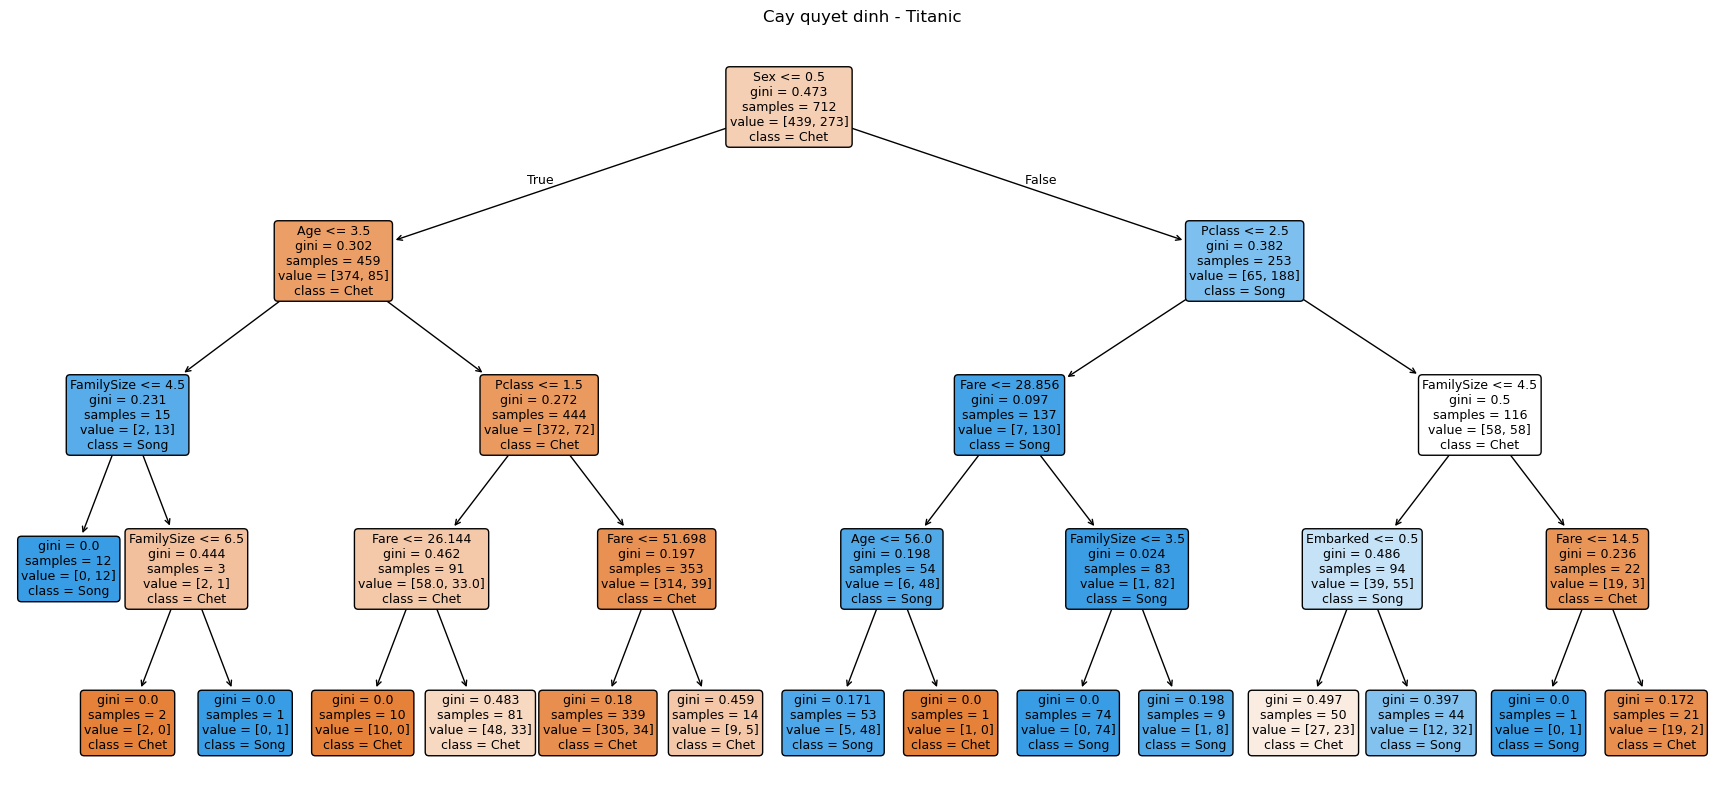

In [3]:
importance = pd.Series(forest.feature_importances_, index=features).sort_values(ascending=False)
print("\nDo quan trong cua cac thuoc tinh (rung cay):\n", importance.round(4))

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=features, class_names=["Chet", "Song"], filled=True, rounded=True, fontsize=9)
plt.title("Cay quyet dinh - Titanic")
plt.savefig("cay_quyet_dinh.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Trực quan hóa độ quan trọng của thuộc tính

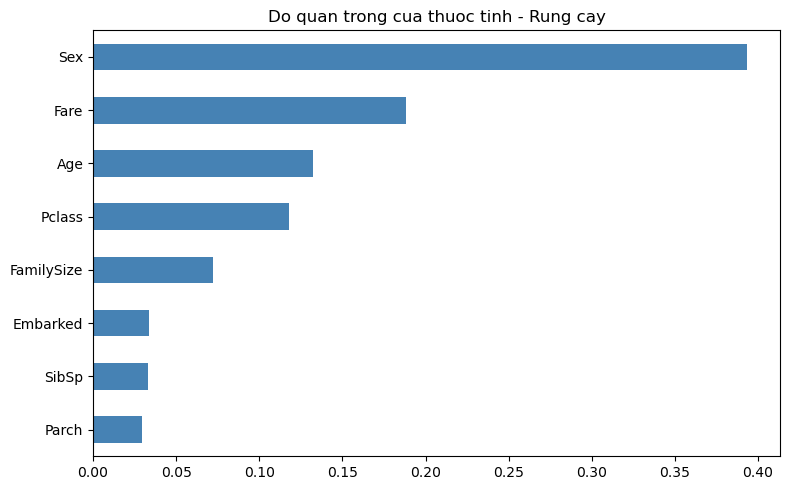

In [4]:
plt.figure(figsize=(8, 5))
importance.sort_values().plot(kind="barh", color="steelblue")
plt.title("Do quan trong cua thuoc tinh - Rung cay")
plt.tight_layout()
plt.savefig("do_quan_trong_thuoc_tinh.png", dpi=150)
plt.show()

## 5. Trực quan hóa ma trận nhầm lẫn

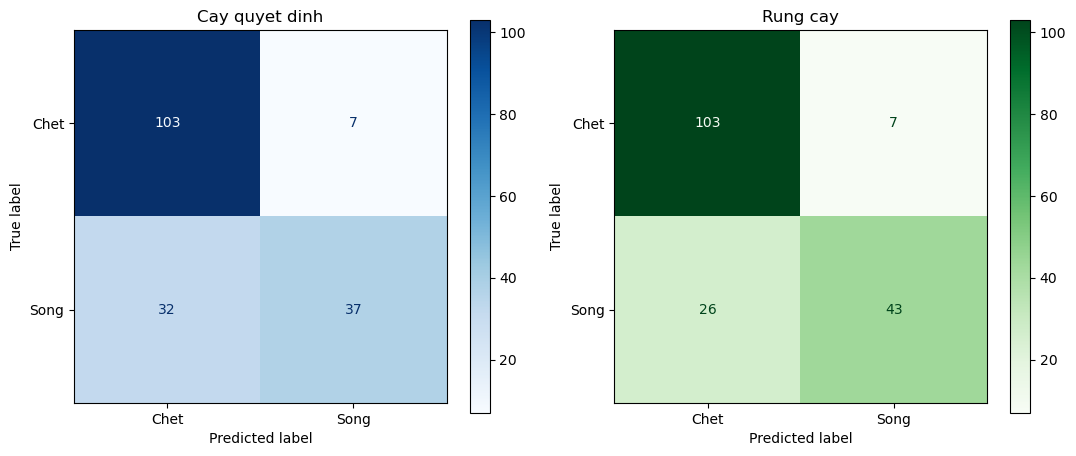

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, tree_pred, display_labels=["Chet", "Song"], ax=axes[0], cmap="Blues")
axes[0].set_title("Cay quyet dinh")
ConfusionMatrixDisplay.from_predictions(y_test, forest_pred, display_labels=["Chet", "Song"], ax=axes[1], cmap="Greens")
axes[1].set_title("Rung cay")
plt.tight_layout()
plt.savefig("ma_tran_nham_lan.png", dpi=150)
plt.show()